# From "I have this dataset" to clean epochs around TMS pulses

This walks through finding a usable recording in ds008037, checking it, and cutting epochs around
its TMS pulses. It uses public, de-identified data.

**You will need** `TMSEEG_DATA_ROOT` set, and these already run:

```
tmseeg-access download --tier metadata
tmseeg-access download --tier signal --subjects sub-001 --tasks tmseeg
tmseeg-access catalog
tmseeg-access check
```

"Clean" here means the markers are trustworthy and known problems are avoided. These epochs have
not been through a full TMS-EEG cleaning pipeline, so they are a starting point for analysis.

## 1. Open the dataset

Opening it reads no signal.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from tmseeg_access.catalog import default_path, query
from tmseeg_access.dataset import Dataset, DuplicatePulseError

ds = Dataset()
catalog = default_path(ds.root)
print(ds)
ds.recordings("sub-001")

Dataset('E:\\tms-eeg-data\\ds008037', subjects=123)


,subject,task,acquisition,has_header,has_signal
0,sub-001,rest,NaN,False,False
1,sub-001,tmseeg,control,True,True
2,sub-001,tmseeg,parietal,True,True
3,sub-001,tmseeg,prefrontal,True,True
4,sub-001,tmseeg,premotor,True,True
5,sub-001,workingmemory,NaN,False,False


## 2. Find runs worth using

The catalog answers this with SQL. Here we look for parietal runs with 120 pulses and no
error-level issue, and join in participant fields.

In [2]:
query(catalog, '''
    WITH problem_runs AS (
        SELECT DISTINCT recording_id FROM issues
        WHERE severity = 'error' AND recording_id IS NOT NULL
    )
    SELECT r.subject, p.age, p.sex, r.pulse_count, r.channels_sidecar, r.has_signal
    FROM recordings r
    JOIN participants p USING (subject)
    LEFT JOIN problem_runs x USING (recording_id)
    WHERE r.acquisition = 'parietal' AND r.pulse_count = 120 AND x.recording_id IS NULL
    ORDER BY r.has_signal DESC, r.subject
    LIMIT 5
''')

,subject,age,sex,pulse_count,channels_sidecar,has_signal
0,sub-001,22,female,120,62,True
1,sub-029,21,male,120,63,True
2,sub-071,27,male,120,63,True
3,sub-092,28,female,120,63,True
4,sub-125,34,female,120,62,True


## 3. Check what the quality rules say about this subject

In [3]:
query(catalog, '''
    SELECT rule, severity, recording_id, "where", observed
    FROM issues WHERE subject = 'sub-001' ORDER BY severity, recording_id
''')

,rule,severity,recording_id,where,observed
0,signal.residual_pulse_artifact,error,sub-001_task-tmseeg_acq-prefrontal,-10 to 22 ms around pulses,"median deviation peaks at 9800.6 uV, 5 ms afte..."
1,signal.reference_channel_active,warning,sub-001_task-tmseeg_acq-control,channel FCZ,"sidecar reference is FCz, but that channel has..."
2,signal.reference_channel_active,warning,sub-001_task-tmseeg_acq-parietal,channel FCZ,"sidecar reference is FCz, but that channel has..."
3,signal.reference_channel_active,warning,sub-001_task-tmseeg_acq-prefrontal,channel FCZ,"sidecar reference is FCz, but that channel has..."
4,signal.reference_channel_active,warning,sub-001_task-tmseeg_acq-premotor,channel FCZ,"sidecar reference is FCz, but that channel has..."
5,signal.residual_pulse_artifact,warning,sub-001_task-tmseeg_acq-premotor,2 to 11 ms around pulses,"median deviation peaks at 69.3 uV, 4 ms after ..."


sub-001's parietal run has no issues. Its prefrontal run does, which we come back to in step 6.

## 4. Look at the pulses

`pulses()` shows the markers as published, with their spacing. `is_duplicate` flags suspected
duplicates but removes nothing. Times come from `onset`, because the `sample` column is 1-based.

In [4]:
pulses = ds.pulses("sub-001", "parietal")
print(len(pulses), "pulses,", int(pulses["is_duplicate"].sum()), "suspected duplicates")
pulses[["onset", "sample", "onset_sample", "gap_from_previous_s", "is_duplicate"]].head()

120 pulses, 0 suspected duplicates


,onset,sample,onset_sample,gap_from_previous_s,is_duplicate
0,8.7837,8785,8784,NaN,False
1,11.7845,11786,11784,3.0008,False
2,15.1739,15175,15174,3.3894,False
3,18.0348,18036,18035,2.8609,False
4,20.9919,20993,20992,2.9571,False


## 5. Cut the epochs

`baseline` is off unless you ask for it, and we end it 10 ms before the pulse. Most recordings
carry a flat `TRIGGER` channel typed as EEG, so we exclude it by name. sub-001 does not have one,
so here that does nothing, but it makes this code safe for other subjects.

The choices made are stored with the epochs.

In [5]:
epochs = ds.epochs_around_pulses(
    "sub-001", "parietal",
    tmin=-0.1, tmax=0.5,
    baseline=(-0.1, -0.01),
    exclude_channels=("TRIGGER",),
)
print(epochs)
print(json.dumps(json.loads(epochs.info["description"]), indent=2))
epochs.metadata.head(3)

<Epochs | 120 events (all good), -0.1 – 0.5 s (baseline -0.1 – -0.01 s), ~34.2 MiB, data loaded, with metadata,
 'parietal': 120>
{
  "source": "sub-001_task-tmseeg_acq-parietal",
  "on_duplicate": "error",
  "duplicate_gap_s": 0.002,
  "markers_in_events_tsv": 120,
  "duplicates_removed": 0,
  "longest_duplicate_group_s": 0.0,
  "channels_excluded": [],
  "epochs_lost_at_recording_edges": 0,
  "tmin": -0.1,
  "tmax": 0.5,
  "baseline": [
    -0.1,
    -0.01
  ]
}


,subject,acquisition,event_id,onset,onset_sample,gap_from_previous_s
0,sub-001,parietal,event-000001,8.7837,8784,NaN
1,sub-001,parietal,event-000002,11.7845,11784,3.0008
2,sub-001,parietal,event-000003,15.1739,15174,3.3894


## 6. See why checking the run matters

Global field power (the spread across channels at each moment) summarises the response in one
line. Both runs below are from the same person and were processed the same way, but the prefrontal
run still contains the TMS artifact. Note how far apart the two scales are.

parietal: field power peaks at 14.3 uV
prefrontal: field power peaks at 300.3 uV


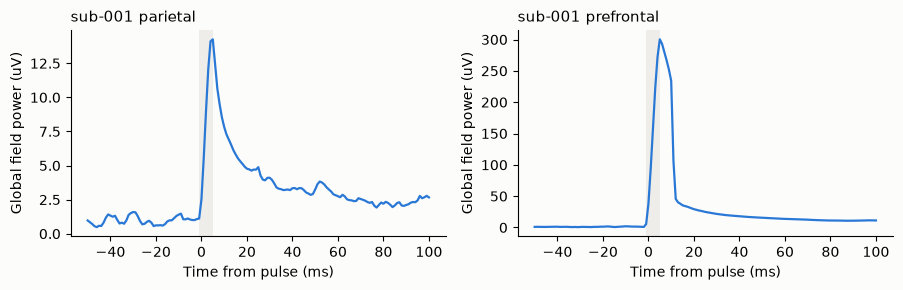

In [6]:
def field_power(site):
    epochs = ds.epochs_around_pulses(
        "sub-001", site, tmin=-0.05, tmax=0.1, baseline=(-0.05, -0.01),
        exclude_channels=("TRIGGER",),
    )
    average = epochs.average()
    return average.times * 1000, average.data.std(axis=0) * 1e6

figure, axes = plt.subplots(1, 2, figsize=(9, 3), facecolor="#fcfcfb")
for axis, site in zip(axes, ["parietal", "prefrontal"]):
    times, power = field_power(site)
    print(f"{site}: field power peaks at {power.max():.1f} uV")
    axis.plot(times, power, color="#2a78d6", linewidth=1.6)
    axis.axvspan(-1, 5, color="#eeede9", linewidth=0)
    axis.set_title(f"sub-001 {site}", loc="left", fontsize=11)
    axis.set_xlabel("Time from pulse (ms)")
    axis.set_ylabel("Global field power (uV)")
    axis.set_facecolor("#fcfcfb")
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout()

The grey band is the -1 to 5 ms window the preprint says was interpolated. Compare the two y-axes:
the prefrontal run peaks far higher, and stays high until about 10 ms after the pulse, which the
parietal run does not.

The check in step 3 reported a much bigger number for this run, because it measures deviation on
each channel. Field power only counts differences between channels, so anything every channel shares
drops out. The two numbers answer different questions, so quote the one you mean.

## 7. When a run has doubled markers

Some runs have pulse markers recorded twice. Epoching refuses them by default, and explains why.

In [7]:
try:
    ds.epochs_around_pulses("sub-136", "parietal")
except DuplicatePulseError as error:
    print(error)

sub-136 parietal: 120 of 240 markers are within 0.002 s of the previous one (QC rule pulse.duplicate). Review them, then pass on_duplicate='keep_first' to keep the first of each group.


If you have reviewed the run and accept treating each pair as one pulse, say so. The choice is
recorded. If you need sub-136, first run:

```
tmseeg-access download --tier signal --subjects sub-136 --tasks tmseeg
```

In [8]:
doubled = ds.epochs_around_pulses(
    "sub-136", "control", on_duplicate="keep_first", exclude_channels=("TRIGGER",),
)
record = json.loads(doubled.info["description"])
{key: record[key] for key in ["markers_in_events_tsv", "duplicates_removed", "channels_excluded"]}

{'markers_in_events_tsv': 240,
 'duplicates_removed': 120,
 'channels_excluded': ['TRIGGER']}

## 8. Hand the epochs to MATLAB

`docs/matlab.md` shows how to open these files.

In [9]:
import tempfile
from pathlib import Path

from tmseeg_access.matlab import export_epochs_mat, read_epochs_mat

folder = Path(tempfile.mkdtemp())
path = export_epochs_mat(epochs, folder / "sub-001_parietal_epochs.mat")
back = read_epochs_mat(path)
print(back["data_uv"].shape, back["provenance"]["source"])
np.abs(back["data_uv"] - epochs.get_data() * 1e6).max()

(120, 62, 601) sub-001_task-tmseeg_acq-parietal


np.float64(0.0)